# Synthetic generator v1: a guide to playing with every option

This notebook walks through **every parameter** of the generator `tree_generator.py` (version 1). For each one it explains what it does, why it exists and what happens when you change it, with figures comparing several values.

**What does the generator do?** It takes a label map (a brain segmentation) and produces an unlimited number of *(synthetic image, segmentation)* pairs. Every image has random shape, contrast, resolution and artefacts. A segmentation network trained on these pairs learns to recognise **the anatomy** rather than one particular kind of MRI scan. This is the idea behind **SynthSeg** (Billot et al., 2023). Our difference is that the intensities come from a **label tree** (an ontology), so related structures get similar intensities.

**What is new in v1 compared with v0**

1. Labels are saved as **uint16**, never uint8. NextBrain has ~333 labels and uint8 only goes up to 255.
2. **Resolution augmentation** as in SynthSeg: a thick-slice acquisition (or a low-resolution isotropic one) is simulated and the image is brought back to the 0.75 mm grid. The simulated resolution also decides which tree nodes are visible.

### How to use this notebook

- Run the cells in order. The cells in section 0 are required.
- Cells marked **✏️ TRY IT** are meant for you to change the values and run again.
- To compare settings you **do not need to rebuild the generator**: `gen.with_config(parameter=value)` creates a variant that shares the templates already in memory. It is instant.
- **Section 11** is a playground with every parameter at once.

### Pipeline overview

```
 OFFLINE (once per template)
   seg 1 mm ─► [1] raw labels ─► [2] super-resolution ─► 0.25 mm template (uint16, cached)

 ONLINE (every sample)
   [0] draw the ACQUISITION: native / isotropic / thick slices (spacing, thickness, alpha)
                │
                ▼  (decides which tree nodes are visible)
   ── at 0.25 mm ────────────────────────────────────────────────────────────
   [3] erosion/dilation ─► [4] affine + elastic deformation
   ── at 0.75 mm ────────────────────────────────────────────────────────────
   [5] partial volume ─► [6] tree intensities ─► [7] bias field ─► motion
                                                               │
   [8] RESOLUTION: slice profile (blur) ─► downsampling ─► noise ─► back to 0.75 mm
                                                               │
   [9] normalisation to [0, 1]          target segmentation: ALWAYS sharp at 0.75 mm
```

| section | steps | parameters |
|---|---|---|
| 3 | 1-2 | `target_voxel`, `factor`, `background`, `output_labels`, `unassigned` |
| 5 | 3 | `morpho_pairs`, `morpho_iter`, `morpho_prob` |
| 6 | 4 | `rotations`, `zooms`, `shears`, `translations_mm`, `elastic_dmax_mm`, `elastic_ctrl` |
| 7 | 5-6 | `colors_mu`, `colors_sigma`, `min_sigma`, `intensity_scale`, `contrasts`, `tree_resolution`, `resolution` |
| 8 | 7 | `bias_*`, `motion_*`, `noise_sigma` |
| 9-10 | 0, 8 | `lowres_*`, `noise_space` |

## 0. Setup

We import the generator and a few plotting functions from `run_example.py`. We use the GPU with the most free memory: the 0.25 mm template has ~500 million voxels (~1 GB in int16).

In [1]:
import json
import math
import os
import random

import matplotlib
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import torch

import tree_generator as tg
from tree_sampling import LabelTree
from run_example import axial, coronal, random_label_cmap

%matplotlib inline
plt.rcParams['figure.dpi'] = 80

if torch.cuda.is_available():
    free = [torch.cuda.mem_get_info(i)[0] for i in range(torch.cuda.device_count())]
    DEVICE = f'cuda:{int(np.argmax(free))}'
else:
    DEVICE = 'cpu'
print('device:', DEVICE)

INPUTS = 'data/inputs'
SEG = f'{INPUTS}/seg.nii.gz'                     # segmentation (1 mm, FreeSurfer labels)
T1 = f'{INPUTS}/T1w.nii.gz'                      # real image (for comparison only)
TREE = f'{INPUTS}/synthseg_ctx_tree.json'        # label tree (intensity model)
CONFIG = 'configs/freesurfer.json'               # base config
CACHE = 'data/outputs/templates'                 # cached super-resolved templates

device: cuda:3


## 1. Helper functions

- `view(gen, n, ...)`: generates `n` samples and plots, for each, an axial slice, a coronal slice and the segmentation.
- `compare({'name': gen, ...})`: one sample per variant with **the same seed**, so the differences come mostly from the changed parameter.
- `aniso_acq(...)` / `iso_acq(...)`: build a fixed acquisition for the resolution step, instead of drawing one.

We show coronal slices because the thick slices of the acquisitions are mostly along axis 2 (axial). An axial slice falls *inside* a thick slice and looks almost sharp. The coronal slice shows the blurring across slices.

In [2]:
def acq_title(acq):
    # Short description of an acquisition
    if acq['mode'] == 'none':
        return 'native 0.75 mm'
    if acq['mode'] == 'iso':
        return f"iso {acq['spacing_mm'][0]:.1f} mm"
    a = acq['axis']
    return f"axis {a}: {acq['spacing_mm'][a]:.1f} mm (thick {acq['thickness_mm'][a]:.1f})"


def draw(gen, seed=0, **kw):
    # One reproducible sample: fix the seed and call the generator
    tg.seed_everything(seed)
    img, seg, aff, info = gen(template_index=0, **kw)
    return img[0].cpu().numpy(), seg.cpu().numpy(), aff, info


def view(gen, n=4, seed=0, views=('axial', 'coronal', 'seg'), **kw):
    # n samples (seeds seed, seed+1, ...), one per column
    fig, axes = plt.subplots(len(views), n, figsize=(2.7 * n, 2.8 * len(views)), squeeze=False)
    infos = []
    for i in range(n):
        img, seg, aff, info = draw(gen, seed + i, **kw)
        infos.append(info)
        for r, c in enumerate(views):
            ax = axes[r, i]
            if c == 'seg':
                ax.imshow(axial(seg, aff, POINT), cmap=LCMAP, vmin=0, vmax=gen.nb_labels - 1, interpolation='nearest')
            else:
                ax.imshow((axial if c == 'axial' else coronal)(img, aff, POINT), cmap='gray', vmin=0, vmax=1)
            ax.axis('off')
        axes[0, i].set_title(f"{info['contrast']} | {acq_title(info['acquisition'])}\n"
                             f"{len(info['class_names'])} classes", fontsize=8)
    plt.tight_layout(); plt.show()
    return infos


def compare(variants, seed=0, views=('axial', 'coronal'), **kw):
    # variants: {'name': gen} or {'name': (gen, call_kwargs)}; same seed for all of them
    n = len(variants)
    fig, axes = plt.subplots(len(views), n, figsize=(2.8 * n, 2.8 * len(views)), squeeze=False)
    for i, (name, v) in enumerate(variants.items()):
        g, extra = v if isinstance(v, tuple) else (v, {})
        img, seg, aff, info = draw(g, seed, **{**kw, **extra})
        for r, c in enumerate(views):
            ax = axes[r, i]
            if c == 'seg':
                ax.imshow(axial(seg, aff, POINT), cmap=LCMAP, vmin=0, vmax=g.nb_labels - 1, interpolation='nearest')
            else:
                ax.imshow((axial if c == 'axial' else coronal)(img, aff, POINT), cmap='gray', vmin=0, vmax=1)
            ax.axis('off')
        axes[0, i].set_title(name, fontsize=9)
    plt.tight_layout(); plt.show()


def aniso_acq(axis=2, spacing=5.0, thickness=None, alpha=1.0, r=0.75):
    # Fixed thick-slice acquisition along `axis` (thickness defaults to the spacing)
    thickness = spacing if thickness is None else thickness
    sp, th, sg = [r] * 3, [r] * 3, [0.] * 3
    sp[axis], th[axis] = spacing, thickness
    sg[axis] = tg.sigma_thick_vox(thickness, alpha, r)
    return dict(mode='aniso', axis=axis, spacing_mm=sp, thickness_mm=th, alpha=[alpha] * 3, sigma_vox=sg)


def iso_acq(voxel=3.0, thickness=None, alpha=1.0, r=0.75):
    # Low-resolution isotropic acquisition
    thickness = voxel if thickness is None else thickness
    s = tg.sigma_thick_vox(thickness, alpha, r)
    return dict(mode='iso', axis=None, spacing_mm=[voxel] * 3, thickness_mm=[thickness] * 3,
                alpha=[alpha] * 3, sigma_vox=[s] * 3)


NATIVE = dict(mode='none', axis=None, spacing_mm=[.75] * 3, thickness_mm=[.75] * 3,
              alpha=[1.] * 3, sigma_vox=[0.] * 3)

## 2. The configuration: every parameter

All the parameters live in the `TreeGeneratorConfig` *dataclass*. There are three ways to set them (from lowest to highest priority):

1. the dataclass defaults (in `tree_generator.py`);
2. a JSON file: `TreeGeneratorConfig.from_json('configs/freesurfer.json', field=value, ...)`;
3. `gen.with_config(field=value)` on an existing generator (or, in `run_example.py`, one command-line option per field: `--lowres-prob 1`).

**Convention:** when a parameter is a **range** `(lo, hi)`, a uniform value in that interval is drawn for each image. When it is a **maximum** `m` (rotations, zoom, ...), the value is drawn in `(-m, m)`.

The table below lists every field with its default, the value in `freesurfer.json` and an explanation.

In [3]:
EXPLANATION = {
    'target_voxel': 'Voxel size (mm) of the output images and segmentations (training grid).',
    'factor': 'The template is super-resolved to target_voxel/factor (0.25 mm). Each output voxel contains factor³ = 27 HR voxels, which gives the partial volume.',
    'background': 'Raw value of the background label. In the output it is always index 0.',
    'output_labels': "'templates': only the labels present in the templates; 'tree': every label of the tree (useful if the templates do not have them all).",
    'unassigned': "What to do with template labels that are not in the tree: 'error' (stop) or 'background' (send them to background).",
    'morpho_pairs': 'Pairs (a, b) of label groups (tree node, label value or a list of those). In each pair, one of the two grows at the expense of the other.',
    'morpho_iter': 'Range of HR voxel layers (0.25 mm) grown by the winning group: (1, 4) = between 0.25 and 1 mm.',
    'morpho_prob': 'Probability of applying each pair in each sample.',
    'rotations': 'Maximum rotation (degrees) about each axis: U(-r, r).',
    'zooms': 'Maximum zoom: scale 1 + U(-z, z) along each axis.',
    'shears': 'Maximum shear.',
    'translations_mm': 'Maximum translation (mm).',
    'elastic_dmax_mm': 'Maximum elastic displacement (mm): how much the structures bend.',
    'elastic_ctrl': 'Control points per axis of the elastic field: few = smooth, global deformation; many = local deformation.',
    'colors_mu': 'Range of the principal colors (GM, WM, CSF), i.e. the base mean of each tissue, in tree units (0-255).',
    'colors_sigma': 'Range of the base standard deviation of each principal color (texture inside each tissue).',
    'min_sigma': 'Lower bound of the standard deviation of every label.',
    'intensity_scale': 'The image is divided by this value before the artefacts, so that noise_sigma is on the [0, 1] scale of SynthSeg.',
    'tree_resolution': "Which resolution decides node visibility: 'acquisition' (that of the drawn acquisition) or 'config' (the resolution field, as in v0).",
    'resolution': "Only with tree_resolution='config': None (= target_voxel), a number or a (lo, hi) range in mm.",
    'contrasts': "List of contrasts; one is drawn per image and used for the per-contrast r_max. None = r_max 'default'.",
    'bias_prob': 'Probability of applying a bias field (intensity inhomogeneity).',
    'bias_vmax': 'Bias field amplitude: the image is multiplied by values in (1 - v, 1 + v).',
    'bias_ctrl': 'Bias field control points per axis: more = more local variations.',
    'motion_prob': 'Probability of motion artefacts (ghosting, blurring).',
    'motion_shots': 'Number of k-space "shots"; in each one the head is in a different position.',
    'motion_rotations': 'Maximum rotation (degrees) between shots.',
    'motion_translations_mm': 'Maximum translation (mm) between shots.',
    'noise_sigma': 'Range of the standard deviation of the Gaussian noise (image on a ~[0, 1] scale).',
    'lowres_prob': 'Probability of simulating a lower-resolution acquisition (otherwise the image stays at 0.75 mm).',
    'lowres_iso_prob': 'If degraded: probability that the acquisition is isotropic (otherwise thick slices along one axis).',
    'lowres_max_iso': 'Maximum isotropic voxel size (mm).',
    'lowres_max_aniso': 'Maximum slice spacing (mm) of the anisotropic acquisitions.',
    'lowres_alpha': 'Range of alpha: small random variation of the slice-profile width (SynthSeg: 1/1.03-1.03).',
    'lowres_random_thickness': 'True: thickness ~ U(0.75, spacing), there may be a gap between slices. False: thickness = spacing.',
    'noise_space': "'lowres': noise is added on the low-resolution grid (realistic: it becomes correlated across slices). 'highres': before the resolution step (SynthSeg's order).",
}

base = tg.TreeGeneratorConfig()
cfg = tg.TreeGeneratorConfig.from_json(CONFIG)
from dataclasses import fields as dc_fields
assert set(EXPLANATION) == {f.name for f in dc_fields(base)}, 'some field is not explained'

def fmt(v):
    s = json.dumps(v)
    return s if len(s) < 40 else s[:37] + '...'

print(f"{'field':25s} {'default':22s} {'freesurfer.json':22s} explanation")
print('-' * 150)
for k, v in base.to_dict().items():
    vj = cfg.to_dict()[k]
    print(f"{k:25s} {fmt(v):22s} {(fmt(vj) if vj != v else '='):22s} {EXPLANATION[k]}")

field                     default                freesurfer.json        explanation
------------------------------------------------------------------------------------------------------------------------------------------------------
target_voxel              0.75                   =                      Voxel size (mm) of the output images and segmentations (training grid).
factor                    3                      =                      The template is super-resolved to target_voxel/factor (0.25 mm). Each output voxel contains factor³ = 27 HR voxels, which gives the partial volume.
background                0                      =                      Raw value of the background label. In the output it is always index 0.
output_labels             "templates"            =                      'templates': only the labels present in the templates; 'tree': every label of the tree (useful if the templates do not have them all).
unassigned                "error"                "b

## 3. Templates and label space (steps 1-2)

### 3.1 Super-resolution

The input segmentation is at 1 mm. To simulate **partial volume** (a 0.75 mm voxel that mixes two tissues has an intermediate intensity), the generator works with a **0.25 mm** template. Each output voxel thus contains 3×3×3 = 27 HR voxels.

For each label, the super-resolution does *one-hot → sinc interpolation → Gaussian smoothing (0.5 mm) → argmax*, which smooths the staircase edges. It is done **once** per template and cached (`data/outputs/templates/`). Later runs only read it.

**v1:** the template is saved as **uint16**. Let's check:

In [4]:
cfg = tg.TreeGeneratorConfig.from_json(CONFIG)
templates = tg.build_templates([SEG], TREE, cfg, CACHE, device=DEVICE)
lab_hr, aff_hr = templates[0]
hr_file = f'{CACHE}/seg_hr0.25mm.nii.gz'
print('HR template:', tuple(lab_hr.shape), '| voxel', nib.load(hr_file).header.get_zooms(),
      '| dtype on disk:', nib.load(hr_file).get_data_dtype())
print('distinct labels:', len(torch.unique(lab_hr)), '| max value:', int(lab_hr.max()))
print('dtype used to save labels with max value 2035:', tg.label_dtype(0, 2035).__name__,
      '| with 70000:', tg.label_dtype(0, 70000).__name__)

HR template: (720, 888, 780) | voxel (np.float32(0.25), np.float32(0.25), np.float32(0.25)) | dtype on disk: uint16
distinct labels: 99 | max value: 2035
dtype used to save labels with max value 2035: uint16 | with 70000: int32


### 3.2 The generator and the label space

`TreeGenerator(templates, tree, config)` converts the raw label values (2, 3, 1001, 2035, ...) into consecutive **indices** `0..K-1` (0 = background):

- `gen.labels[i]`: raw value of index `i`;
- `gen.index[value]`: index of a raw value;
- `gen.label_names()`: name (tree node) of each index.

The segmentation returned by `gen()` is in indices (int16 internally, up to 32767 labels). `tg.save_sample(..., labels=gen.labels)` saves it with the raw values.

Parameters of this part (they cannot be changed with `with_config`, because they change the label space or the grid):

- **`output_labels`**: `'templates'` uses only the labels that appear in the templates. `'tree'` uses every label of the tree, even if some never appear. This is useful so that all datasets share the same numbering.
- **`unassigned`**: template labels that are not in the tree either raise an error (`'error'`) or are sent to background (`'background'`). `freesurfer.json` uses `'background'`.
- **`background`**: raw value of the background.
- **`target_voxel`, `factor`**: output grid and super-resolution factor.

In [5]:
gen = tg.TreeGenerator(templates, TREE, cfg, device=DEVICE)
print(f'{gen.nb_labels} output labels ({len(gen.morpho_pairs)} morphology pairs)')
names = gen.label_names()
for i in [0, 1, 2, 10, 40, gen.nb_labels - 1]:
    print(f'  index {i:3d} -> raw value {gen.labels[i]:5d} -> {names[i]}')

# with output_labels='tree' the output includes every label of the tree
gen_tree = tg.TreeGenerator(templates, TREE, tg.TreeGeneratorConfig.from_json(CONFIG, output_labels='tree'), device='cpu')
print(f"output_labels='tree': {gen_tree.nb_labels} labels")
del gen_tree

# display point (centre of the brain) and label colormap
centre = torch.nonzero(gen.templates[0][0] > 0).float().mean(0).cpu().numpy()
POINT = (aff_hr @ np.append(centre, 1))[:3]
LCMAP = random_label_cmap(gen.nb_labels)

99 output labels (11 morphology pairs)
  index   0 -> raw value     0 -> background
  index   1 -> raw value     2 -> cerebral_wm_2
  index   2 -> raw value     4 -> lateral_ventricles_4
  index  10 -> raw value    14 -> third_ventricle
  index  40 -> raw value  1011 -> cortex_1011_2011_1011
  index  98 -> raw value  2035 -> cortex_1035_2035_2035
output_labels='tree': 111 labels


## 4. One sample, step by step

`gen(return_steps=True)` returns every intermediate volume in `info['steps']`. To see each step clearly we force motion (`motion=True`) and an acquisition of **5 mm axial slices** (`acquisition=aniso_acq(2, 5.0)`).

What `gen()` returns:

- `img`: `(1, X, Y, Z)` in [0, 1];
- `seg`: `(X, Y, Z)` indices;
- `affine`: voxel-to-world matrix of the 0.75 mm grid;
- `info`: everything that was drawn (`colors_mu`, `colors_sigma`, `contrast`, `acquisition`, `resolution`, `mus`, `sigmas`, `group_of`, `class_names`, ...).

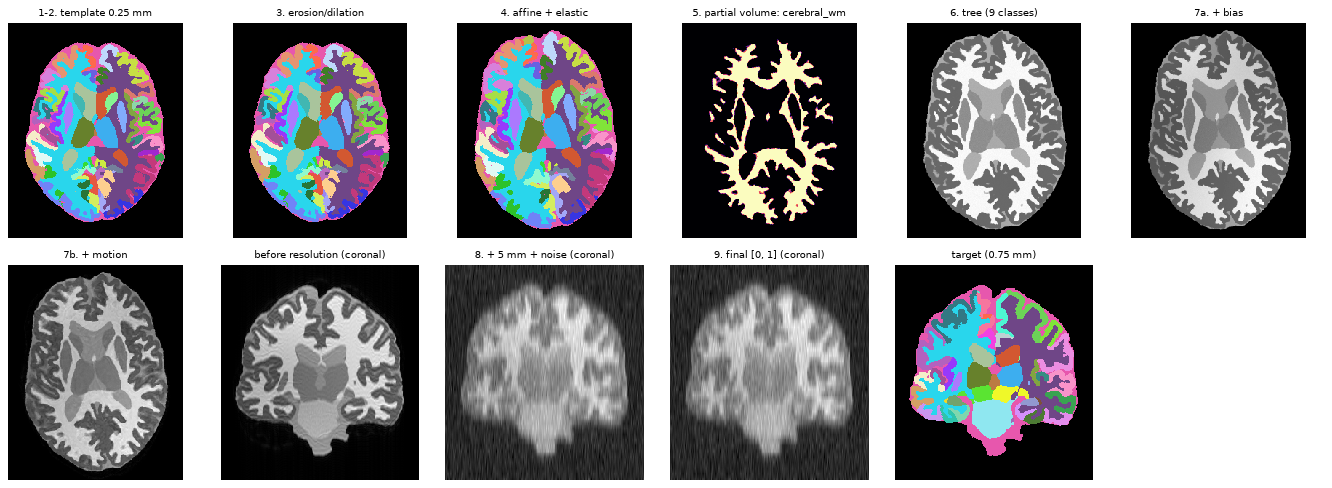

contrast: T1 | tree resolution: 5.0 mm
acquisition: {'mode': 'aniso', 'axis': 2, 'spacing_mm': [0.75, 0.75, 5.0], 'thickness_mm': [0.75, 0.75, 4.0], 'alpha': [1.0, 1.0, 1.0], 'sigma_vox': [0.0, 0.0, 3.91]}
low-resolution image: (240, 296, 39) vs output (240, 296, 260)


In [6]:
tg.seed_everything(3)
img, seg, aff, info = gen(template_index=0, acquisition=aniso_acq(2, 5.0, 4.0), motion=True, return_steps=True)
st = info['steps']
wm = info['group_of'][gen.index[2]]   # generation class of the left white matter
lkw = dict(cmap=LCMAP, vmin=0, vmax=gen.nb_labels - 1)

panels = [
    (axial(gen.templates[0][0].cpu(), aff_hr, POINT), '1-2. template 0.25 mm', lkw),
    (axial(st['morphology'], aff_hr, POINT), '3. erosion/dilation', lkw),
    (axial(st['deformed'], aff_hr, POINT), '4. affine + elastic', lkw),
    (axial(st['pv'][wm], aff, POINT), f"5. partial volume: {info['class_names'][wm]}", dict(cmap='magma')),
    (axial(st['tree'][0], aff, POINT), f"6. tree ({len(info['class_names'])} classes)", {}),
    (axial(st['bias'][0], aff, POINT), '7a. + bias', {}),
    (axial(st['motion'][0], aff, POINT), '7b. + motion', {}),
    (coronal(st['motion'][0], aff, POINT), 'before resolution (coronal)', {}),
    (coronal(st['resolution'][0], aff, POINT), '8. + 5 mm + noise (coronal)', {}),
    (coronal(img[0].cpu(), aff, POINT), '9. final [0, 1] (coronal)', {}),
    (coronal(seg.cpu(), aff, POINT), 'target (0.75 mm)', lkw),
]
fig, axes = plt.subplots(2, 6, figsize=(17, 6.2))
for ax, (im, t, kw) in zip(axes.ravel(), panels):
    ax.imshow(im, interpolation='nearest', **({'cmap': 'gray'} | kw)); ax.set_title(t, fontsize=9); ax.axis('off')
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

print('contrast:', info['contrast'], '| tree resolution:', info['resolution'], 'mm')
print('acquisition:', {k: (np.round(v, 2).tolist() if isinstance(v, list) else v) for k, v in info['acquisition'].items()})
print('low-resolution image:', tuple(st['lowres'].shape[1:]), 'vs output', tuple(img.shape[1:]))

Note two things:

- The **target segmentation** (last panel) is sharp even though the image is at 5 mm. The network learns *low-resolution image → high-resolution segmentation*, as in SynthSeg.
- Internally, step 8 works with an image of `ceil(n / (5/0.75))` slices, which is what the simulated scanner "acquires", and then interpolates it back to the 0.75 mm grid.

## 5. Shape: erosion and dilation (step 3)

Manual and automatic segmentations do not agree exactly on where each structure ends: the white matter / cortex boundary, the size of the ventricles, etc. So that the network does not memorise the exact shape of the template, in each sample some structures **grow** at the expense of their neighbour.

- **`morpho_pairs`**: list of pairs `(a, b)`. Each group can be
  - the **name of a tree node** (all the labels of its subtree: `"cortex"` includes the 68 cortical parcels),
  - a **label value** (`24` = CSF),
  - or a **list** of the above.

  In each sample, and with probability `morpho_prob`, it is decided at random whether *a grows into b* or *b grows into a*. If the growing group has several labels, each new voxel copies the neighbouring label, so the cortical parcels stay consistent.
- **`morpho_iter`**: range of layers grown (each layer = 0.25 mm). `(1, 4)` = between 0.25 and 1 mm.
- **`morpho_prob`**: probability per pair.

The pairs in `freesurfer.json`:

In [7]:
for a, b in cfg.morpho_pairs:
    print(f'  {str(a):20s} <-> {b}')

  cerebral_wm          <-> cortex
  cerebral_wm          <-> lateral_ventricles
  cerebral_wm          <-> inf_lat_ventricles
  cerebral_wm          <-> thalamus
  cerebral_wm          <-> putamen
  cerebral_wm          <-> pallidum
  cerebral_wm          <-> caudate
  cerebral_wm          <-> accumbens
  cerebral_wm          <-> amygdala
  cerebral_wm          <-> hippocampus
  24                   <-> cortex
  24                   <-> vessels


To see it in isolation we apply only step 3 to the HR template, with `morpho_prob=1` and `morpho_iter=(4, 4)` (1 mm, the default maximum). The voxels that change label are shown in red:

changed voxels: 6.66% of the volume


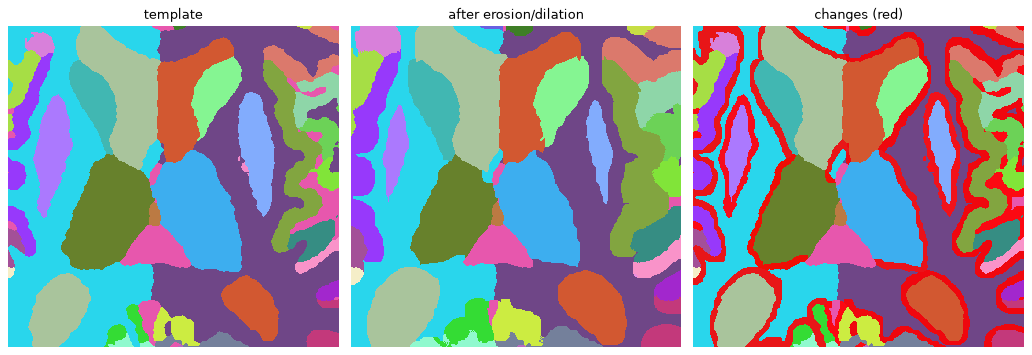

In [8]:
# ✏️ TRY IT: change morpho_iter / morpho_prob / morpho_pairs
g = gen.with_config(morpho_prob=1.0, morpho_iter=(4, 4))
lab0 = g.templates[0][0]
random.seed(0)
lab1 = g._morphology(lab0.clone())
changed = (lab1 != lab0).cpu()
print(f'changed voxels: {changed.float().mean() * 100:.2f}% of the volume')

a0, a1, ac = (axial(v, aff_hr, POINT) for v in (lab0.cpu(), lab1.cpu(), changed))
sl = (slice(250, 600), slice(200, 560))   # zoom
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
axes[0].imshow(a0[sl], interpolation='nearest', **lkw); axes[0].set_title('template')
axes[1].imshow(a1[sl], interpolation='nearest', **lkw); axes[1].set_title('after erosion/dilation')
axes[2].imshow(a0[sl], interpolation='nearest', **lkw)
axes[2].imshow(np.ma.masked_equal(ac[sl], 0), cmap='autumn', alpha=.9, interpolation='nearest'); axes[2].set_title('changes (red)')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

**Things to try**

- `morpho_pairs=[('cortex', 'csf_spaces')]`: thicker or thinner cortex against the CSF.
- `morpho_pairs=[(['thalamus', 'caudate'], 'cerebral_wm')]`: a group made of several nodes.
- `morpho_prob=0`: turns the step off. Same as `morpho_pairs=[]`.

## 6. Spatial deformation (step 4)

An **affine** transform (rotation, zoom, shear, translation) and a smooth **elastic** field are applied to the labels at 0.25 mm with nearest-neighbour interpolation. The field is drawn on the 0.75 mm grid and interpolated to 0.25 mm in blocks, to save memory.

| parameter | meaning | default |
|---|---|---|
| `rotations` | maximum angle per axis (°), U(-r, r) | 10 |
| `zooms` | scale 1 + U(-z, z) | 0.1 |
| `shears` | maximum shear | 0 |
| `translations_mm` | maximum translation (mm) | 0 |
| `elastic_dmax_mm` | maximum elastic displacement (mm) | 7.5 |
| `elastic_ctrl` | control points of the elastic field per axis | 7 |

We compare the same sample (same seed) without deformation, with the defaults and with exaggerated deformations. We use the native acquisition and no motion to see only the shape.

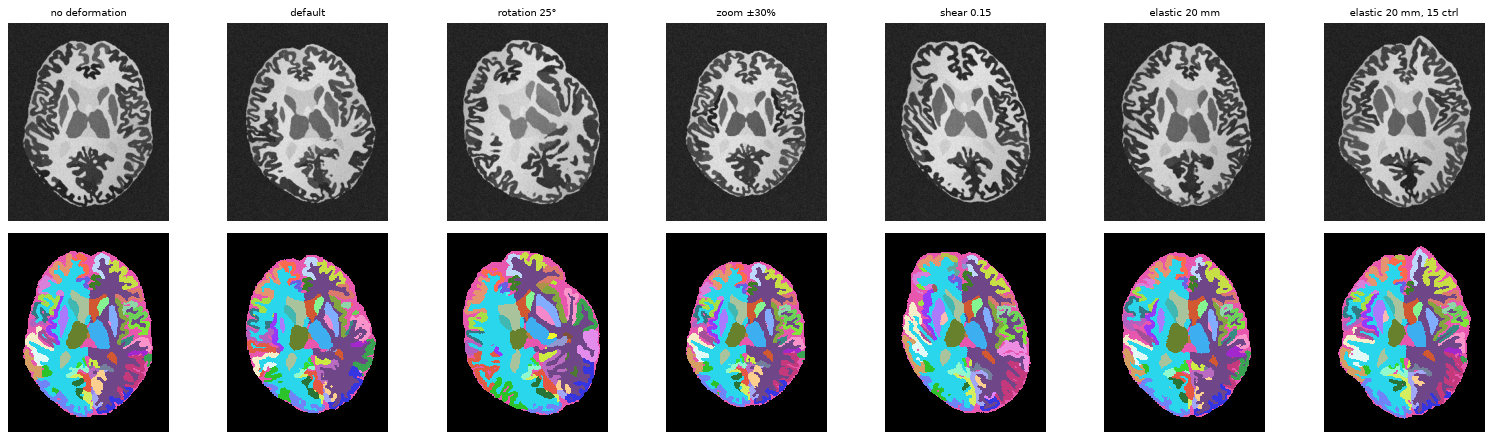

In [9]:
# ✏️ TRY IT
no_def = dict(rotations=0., zooms=0., shears=0., translations_mm=0., elastic_dmax_mm=0.)
compare({
    'no deformation': gen.with_config(**no_def),
    'default': gen,
    'rotation 25°': gen.with_config(**{**no_def, 'rotations': 25.}),
    'zoom ±30%': gen.with_config(**{**no_def, 'zooms': 0.3}),
    'shear 0.15': gen.with_config(**{**no_def, 'shears': 0.15}),
    'elastic 20 mm': gen.with_config(**{**no_def, 'elastic_dmax_mm': 20.}),
    'elastic 20 mm, 15 ctrl': gen.with_config(**{**no_def, 'elastic_dmax_mm': 20., 'elastic_ctrl': 15}),
}, seed=1, views=('axial', 'seg'), acquisition=NATIVE, motion=False)

- With **few control points** (`elastic_ctrl`) the elastic field is smooth and bends the whole brain. With **many**, the deformation is local and can produce unrealistic anatomy if `elastic_dmax_mm` is large.
- `translations_mm` moves the brain within the field of view. With large values it can go past the edge: the FOV is the bounding box of the template plus 16 mm.

## 7. Tree intensities (steps 5-6)

### 7.1 Partial volume

Each 0.75 mm voxel counts how many of its 27 HR voxels belong to each label (`pv`). The voxel intensity is the mixture of the Gaussians of the labels it contains: $I = \sum_g pv_g \cdot \mathcal{N}(\mu_g, \sigma_g)$. The output segmentation is the majority label.

### 7.2 The tree

Each tree node has labels and some weights. For one image:

1. The **principal colors** are drawn: one value per base tissue (GM, WM, CSF), `C ~ U(colors_mu)` and `V ~ U(colors_sigma)`.
2. **Level-1** nodes (white matter, cortex, basal ganglia, ...): `mu = Σ w_mu·C + wr_mu·N(0,1)`, and `sigma` the same way with `V`. For example, the basal ganglia are `0.7·GM + 0.3·WM`.
3. **Deeper** nodes: `mu = mu_parent + wr_mu·N(0,1)`, a small variation around the parent, **only if the node is visible**.
4. A node is **visible** if the resolution is ≤ its `r_max` (which can depend on the contrast). If it is not, it copies the parent's Gaussian exactly. So at low resolution the cortical parcels merge into "cortex".

Labels that share a Gaussian form a **generation class** (`info['class_names']`, `info['group_of']`). In that image they are indistinguishable, which can be used to merge them in the loss.

Here is the tree at 3 mm (`-> parent` = collapsed into the parent):

In [10]:
tree = LabelTree.load(TREE)
print('principal colors:', tree.colors, '| contrasts:', tree.contrasts)
print('\n=== at 3 mm, contrast T1 ===')
tree.print_tree(3.0, 'T1')

principal colors: ['GM', 'WM', 'CSF'] | contrasts: ['T1', 'T2', 'FLAIR', 'PD']

=== at 3 mm, contrast T1 ===
root [L0, r_max=inf, visible]
    background [L1, r_max=inf, visible] labels=[0]
    cerebral_wm [L1, r_max=inf, visible] labels=[2, 41]
        wm_lesions [L2, r_max=2, -> cerebral_wm] labels=[25, 57]
        optic_chiasm [L2, r_max=1.5, -> cerebral_wm] labels=[85]
    cortex [L1, r_max=inf, visible] labels=[3, 42]
        cortex_1001_2001 [L2, r_max=1, -> cortex] labels=[1001, 2001]
        cortex_1002_2002 [L2, r_max=1, -> cortex] labels=[1002, 2002]
        cortex_1003_2003 [L2, r_max=1, -> cortex] labels=[1003, 2003]
        cortex_1005_2005 [L2, r_max=1, -> cortex] labels=[1005, 2005]
        cortex_1006_2006 [L2, r_max=1, -> cortex] labels=[1006, 2006]
        cortex_1007_2007 [L2, r_max=1, -> cortex] labels=[1007, 2007]
        cortex_1008_2008 [L2, r_max=1, -> cortex] labels=[1008, 2008]
        cortex_1009_2009 [L2, r_max=1, -> cortex] labels=[1009, 2009]
        corte

Number of generation classes as a function of resolution and contrast (`r_max` can depend on the contrast):

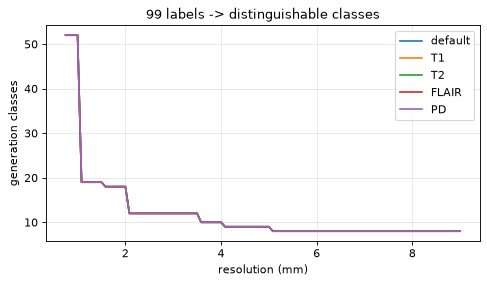

In [11]:
res = np.linspace(0.75, 9, 100)
plt.figure(figsize=(7, 3.5))
for c in [None] + list(tree.contrasts):
    n = [len(gen.scheme.label_set_lut(r, c)[1]) for r in res]
    plt.plot(res, n, label=c or 'default')
plt.xlabel('resolution (mm)'); plt.ylabel('generation classes'); plt.legend(); plt.grid(alpha=.3)
plt.title(f'{gen.nb_labels} labels -> distinguishable classes'); plt.show()

### 7.3 Intensity parameters

- **`colors_mu`** `(lo, hi)`: range of the means of the principal colors. The full range `(0, 255)` gives any contrast, including inverted ones (bright CSF as in T2, or dark as in T1). With a narrow range all tissues look alike and the contrast is low.
- **`colors_sigma`** `(lo, hi)`: base standard deviation (texture inside each tissue). The tree's `wr_sigma` values add to it.
- **`min_sigma`**: lower bound of the sigma of each label (avoids perfectly flat tissues).
- **`intensity_scale`**: the image is divided by this value before the artefacts (255 → ~[0, 1] scale). If you change it, you change the relative weight of `noise_sigma`.

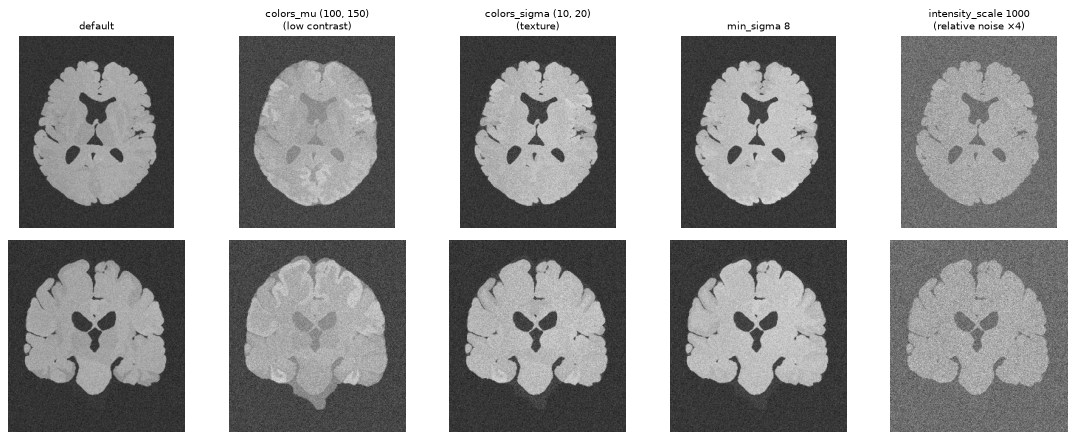

In [12]:
# ✏️ TRY IT
compare({
    'default': gen,
    'colors_mu (100, 150)\n(low contrast)': gen.with_config(colors_mu=(100., 150.)),
    'colors_sigma (10, 20)\n(texture)': gen.with_config(colors_sigma=(10., 20.)),
    'min_sigma 8': gen.with_config(min_sigma=8.),
    'intensity_scale 1000\n(relative noise ×4)': gen.with_config(intensity_scale=1000.),
}, seed=2, acquisition=NATIVE, motion=False)

Several samples with different seeds to see the variety of contrasts (native acquisition, no motion):

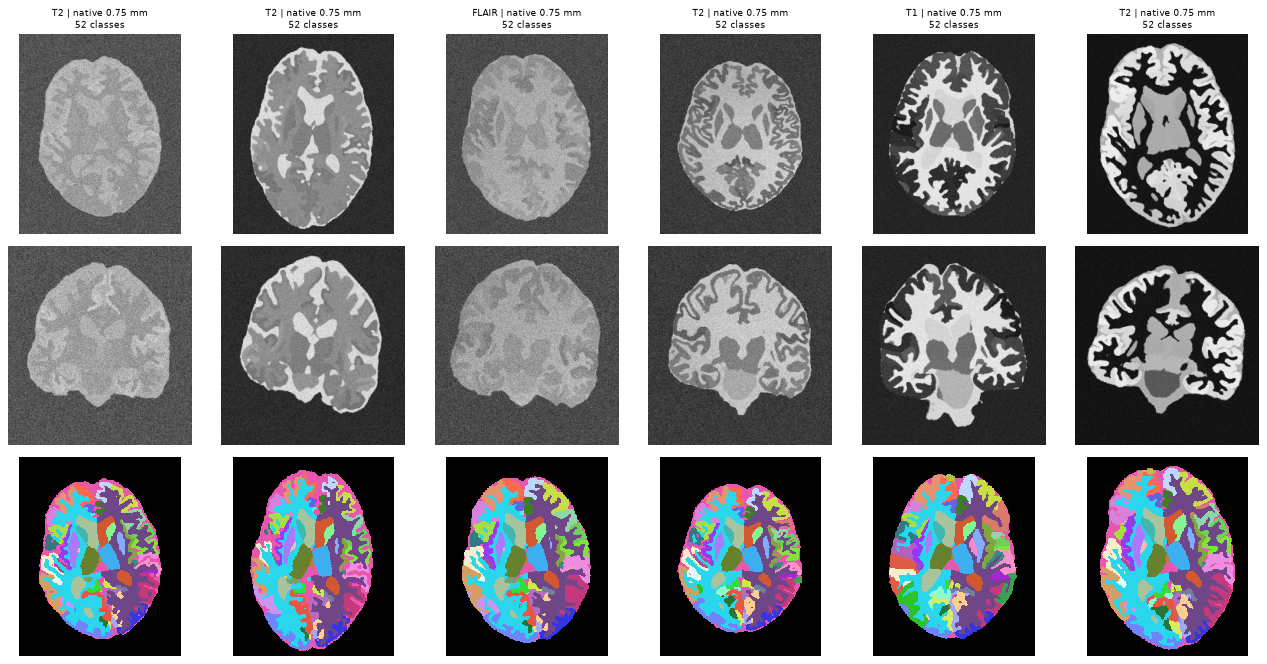

In [13]:
view(gen, n=6, seed=10, acquisition=NATIVE, motion=False);

### 7.4 Contrast and tree resolution

- **`contrasts`**: list of contrasts. One is drawn per image, and it is only used to pick each node's `r_max` (some structures are easier to see in some contrasts than in others). It does not force the image to "look" T1 or T2: that is decided by the drawn colors. With `None` the `'default'` `r_max` is used.
- **`tree_resolution`**:
  - `'acquisition'` (v1, default): the tree resolution is the **coarsest spacing of the drawn acquisition**. An image with 6 mm slices cannot distinguish cortical parcels, and now it paints them the same.
  - `'config'` (v0 behaviour): the resolution is taken from the `resolution` field (`None` = `target_voxel`, a number or a range), independently of the acquisition.

The same sample at 6 mm, with the tree resolution coupled to the acquisition or fixed at 0.75 mm:

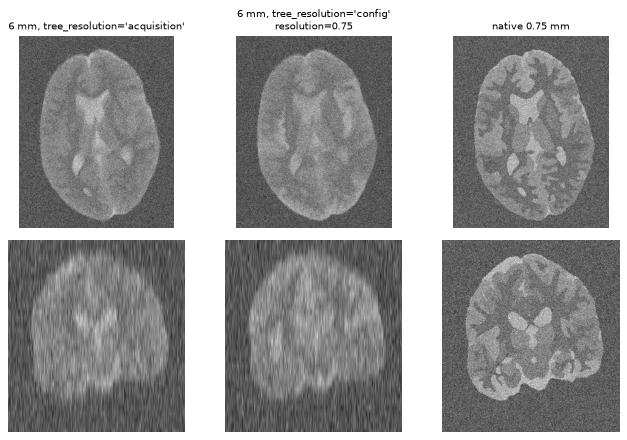

acquisition : tree resolution 6.0 mm -> 8 classes
config 0.75 : tree resolution 0.75 mm -> 52 classes


In [14]:
acq6 = aniso_acq(2, 6.0)
compare({
    "6 mm, tree_resolution='acquisition'": gen,
    "6 mm, tree_resolution='config'\nresolution=0.75": gen.with_config(tree_resolution='config', resolution=0.75),
    'native 0.75 mm': (gen, dict(acquisition=NATIVE)),
}, seed=4, views=('axial', 'coronal'), acquisition=acq6, motion=False)
for name, g in [('acquisition', gen), ('config 0.75', gen.with_config(tree_resolution='config', resolution=0.75))]:
    _, _, _, inf = draw(g, 4, acquisition=acq6, motion=False)
    print(f"{name:12s}: tree resolution {inf['resolution']} mm -> {len(inf['class_names'])} classes")

## 8. Artefacts (step 7 and noise)

### 8.1 Bias field

In MRI the intensity of a given tissue varies slowly in space because of coil inhomogeneity. This is simulated by multiplying the image by a smooth random field.

- **`bias_prob`**: probability of applying it.
- **`bias_vmax`**: the field takes values in `(1 - v, 1 + v)`. With 0.5, a region can end up 50 % brighter or darker.
- **`bias_ctrl`**: control points per axis. Few = global variation, many = local variation.

Below, the image and the field itself (ratio image with bias / image without bias):

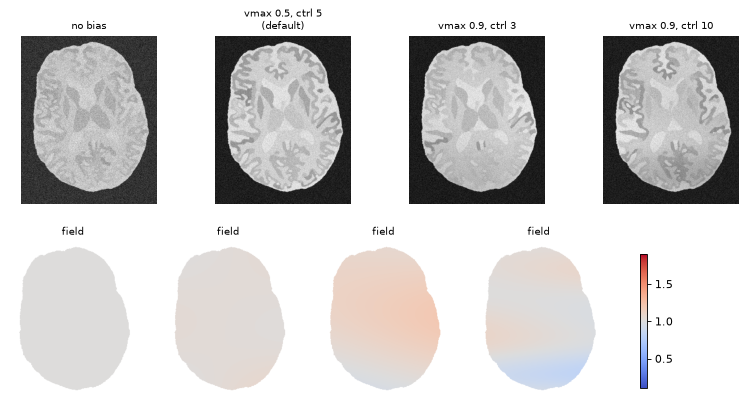

In [15]:
# ✏️ TRY IT
variants = {
    'no bias': gen.with_config(bias_prob=0.),
    'vmax 0.5, ctrl 5\n(default)': gen,
    'vmax 0.9, ctrl 3': gen.with_config(bias_vmax=0.9, bias_ctrl=3),
    'vmax 0.9, ctrl 10': gen.with_config(bias_vmax=0.9, bias_ctrl=10),
}
fig, axes = plt.subplots(2, len(variants), figsize=(3 * len(variants), 6))
for i, (name, g) in enumerate(variants.items()):
    tg.seed_everything(5)
    im, sg, af, inf = g(template_index=0, acquisition=NATIVE, motion=False, return_steps=True)
    t, b = inf['steps']['tree'][0].numpy(), inf['steps']['bias'][0].numpy()
    field = np.where(t > 0.02, b / np.maximum(t, 1e-6), np.nan)
    axes[0, i].imshow(axial(im[0].cpu(), af, POINT), cmap='gray'); axes[0, i].set_title(name, fontsize=9)
    h = axes[1, i].imshow(axial(field, af, POINT), cmap='coolwarm', vmin=0.1, vmax=1.9); axes[1, i].set_title('field', fontsize=9)
for ax in axes.ravel(): ax.axis('off')
plt.colorbar(h, ax=axes[1].tolist(), shrink=.8); plt.show()

### 8.2 Motion

The image is acquired in k-space in several **shots** (`motion_shots`). If the patient moves between shots, each part of k-space corresponds to a different head position. The result is **ghosting** and blurring along the phase-encoding direction.

- **`motion_prob`**: probability per image (`gen(motion=True/False)` forces it on or off).
- **`motion_shots`**: number of shots.
- **`motion_rotations`**, **`motion_translations_mm`**: maximum amplitude of the motion between shots.

The shot that contains the centre of k-space is kept at the reference position. So the image stays aligned with the segmentation and only the artefacts appear.

**Note:** the motion amplitude is drawn for each image (up to the maximum), and so is the phase axis. With a given seed, the "strong" setting may come out with little motion. Try other seeds (`seed=`) to see the variety.

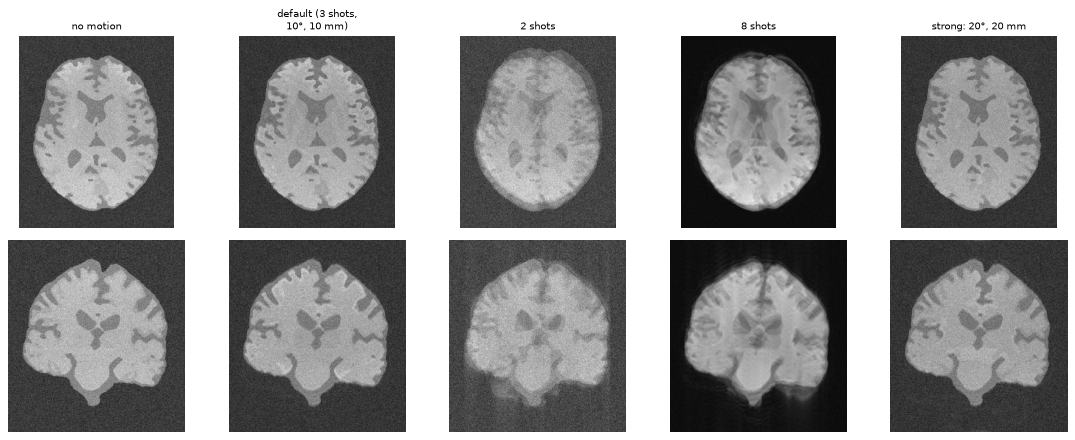

In [16]:
# ✏️ TRY IT
compare({
    'no motion': (gen, dict(motion=False)),
    'default (3 shots,\n10°, 10 mm)': (gen, dict(motion=True)),
    '2 shots': (gen.with_config(motion_shots=2), dict(motion=True)),
    '8 shots': (gen.with_config(motion_shots=8), dict(motion=True)),
    'strong: 20°, 20 mm': (gen.with_config(motion_rotations=20., motion_translations_mm=20.), dict(motion=True)),
}, seed=6, acquisition=NATIVE)

### 8.3 Noise

Gaussian noise with standard deviation `~ U(noise_sigma)`, on the image at a ~[0, 1] scale (before the final normalisation). Where it is added is decided by `noise_space` (section 9.5).

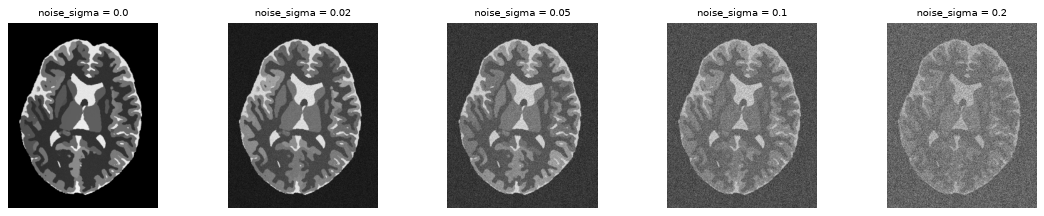

In [17]:
# ✏️ TRY IT
compare({f'noise_sigma = {s}': gen.with_config(noise_sigma=(s, s)) for s in [0., 0.02, 0.05, 0.1, 0.2]},
        seed=7, acquisition=NATIVE, motion=False, views=('axial',))

## 9. Resolution: simulating the acquisition (SynthSeg, sec. 3.1.4)

Clinical MRI scans are rarely 1 mm isotropic: many have **thick slices** (e.g. 1×1×5 mm) in one direction (axial, coronal or sagittal). So that the network works at any resolution, SynthSeg simulates a random acquisition for each image and brings it back to the fine grid. The target segmentation stays sharp.

### 9.1 The equations

We start from the image at $r_{HR}$ = 0.75 mm.

$$
\begin{aligned}
r_{spac} &\sim \mathcal{U}(r_{HR},\ b_{res}) && \text{slice spacing (eq. 20)}\\
r_{thick} &\sim \mathcal{U}(r_{HR},\ r_{spac}) && \text{slice thickness (eq. 21)}\\
\alpha &\sim \mathcal{U}(1/1.03,\ 1.03) && \text{profile variation (eq. 22)}\\
\sigma_{thick} &= \frac{2\alpha\log 10}{2\pi}\,\frac{r_{thick}}{r_{HR}} && \text{width of the Gaussian profile, in voxels (eq. 23)}
\end{aligned}
$$

and then:

1. **slice profile**: Gaussian smoothing $\sigma_{thick}$ along the slice direction (each slice averages the signal over its thickness);
2. **downsampling** to $\lceil n / (r_{spac}/r_{HR}) \rceil$ slices;
3. **noise** on that grid (if `noise_space='lowres'`);
4. linear **interpolation** back to 0.75 mm.

With $r_{thick} < r_{spac}$ there is a **gap** between slices: part of the anatomy is not acquired. This is common in clinical scans.

### 9.2 Implementation with cornucopia

`LowResAcquisitionFinalTransform` is the per-axis generalisation of `cornucopia.LowResSliceFinalTransform`: it uses cornucopia's `smoothnd` and the same interpolation. On a single axis it gives **exactly** the same result (`test_generator.py` checks this). Equivalences:

| cornucopia | here |
|---|---|
| `resolution` (spacing in voxels) | $r_{spac} / r_{HR}$ |
| `thickness` (FWHM as a fraction of the spacing) | $2\sqrt{2\ln 2}\,\sigma_{thick} / (r_{spac}/r_{HR})$ |

`SynthSegLowResTransform` is a cornucopia `NonFinalTransform`. It draws the parameters (`.sample()`) and builds the deterministic transform (`.make_final(prm)`). The generator draws the acquisition **at the start** because it also uses it for the tree.

### 9.3 The parameters and the distribution of acquisitions

| parameter | meaning | default (SynthSeg) |
|---|---|---|
| `lowres_prob` | probability of degrading (otherwise native 0.75 mm image) | 0.95 |
| `lowres_iso_prob` | if degraded: probability of isotropic | 0.1 |
| `lowres_max_iso` | maximum isotropic voxel (mm) | 4 |
| `lowres_max_aniso` | maximum thick-slice spacing (mm), $b_{res}$ | 8 |
| `lowres_alpha` | range of α | (1/1.03, 1.03) |
| `lowres_random_thickness` | `True`: $r_{thick} \sim U(r_{HR}, r_{spac})$; `False`: $r_{thick} = r_{spac}$ | True |

We draw 5000 acquisitions to see the resulting distribution:

{'none': '4.5%', 'iso': '8.7%', 'aniso': '86.9%'}
thick-slice axis: {0: 1462, 1: 1402, 2: 1479}


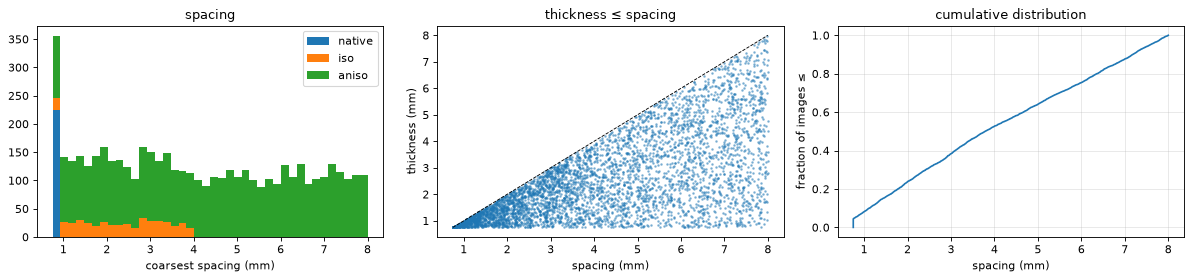

images with spacing ≤ 1 mm: 8.2%  |  ≤ 2 mm: 23.8%


In [18]:
# ✏️ TRY IT: change the parameters and see how the distribution changes
g = gen.with_config(lowres_prob=0.95, lowres_iso_prob=0.1, lowres_max_iso=4., lowres_max_aniso=8.)
random.seed(0)
draws = [g.lowres.sample() for _ in range(5000)]
modes = [d['mode'] for d in draws]
print({m: f'{modes.count(m) / len(modes):.1%}' for m in ('none', 'iso', 'aniso')})
print('thick-slice axis:', {a: sum(d['axis'] == a for d in draws) for a in range(3)})

spac = np.array([max(d['spacing_mm']) for d in draws])
thick = np.array([max(d['thickness_mm']) for d in draws])
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].hist([spac[np.array(modes) == m] for m in ('none', 'iso', 'aniso')], bins=40, stacked=True,
             label=['native', 'iso', 'aniso'])
axes[0].set_xlabel('coarsest spacing (mm)'); axes[0].legend(); axes[0].set_title('spacing')
axes[1].scatter(spac, thick, s=2, alpha=.4); axes[1].plot([0.75, 8], [0.75, 8], 'k--', lw=.8)
axes[1].set_xlabel('spacing (mm)'); axes[1].set_ylabel('thickness (mm)'); axes[1].set_title('thickness ≤ spacing')
axes[2].plot(np.sort(spac), np.linspace(0, 1, len(spac)))
axes[2].set_xlabel('spacing (mm)'); axes[2].set_ylabel('fraction of images ≤'); axes[2].grid(alpha=.3)
axes[2].set_title('cumulative distribution')
plt.tight_layout(); plt.show()
print(f'images with spacing ≤ 1 mm: {np.mean(spac <= 1):.1%}  |  ≤ 2 mm: {np.mean(spac <= 2):.1%}')

With the SynthSeg values, most images are considerably coarser than 0.75 mm. Since the tree resolution follows the acquisition, this also decides **how often the network sees the fine structures with their own intensity** (section 10). If you want it to see more fine images, lower `lowres_prob` or `lowres_max_aniso`.

### 9.4 Spacing and thickness

Axial slices (axis 2) of increasing spacing, always with thickness = spacing. We look at the **coronal** slice, which cuts across the thick slices:

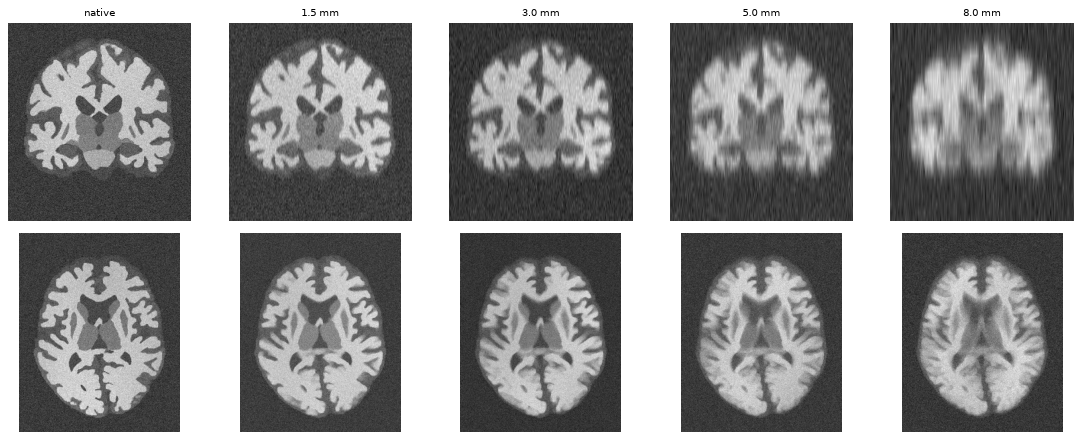

In [19]:
# ✏️ TRY IT
compare({('native' if s == .75 else f'{s} mm'): (gen, dict(acquisition=aniso_acq(2, s) if s > .75 else NATIVE))
         for s in [0.75, 1.5, 3., 5., 8.]}, seed=8, motion=False, views=('coronal', 'axial'))

Effect of the **thickness** with the spacing fixed at 6 mm. With a small thickness there is almost no smoothing: the slices are thin but there is a gap between them. The downsampling causes *aliasing* (staircase edges, structures that vanish). With a large thickness each slice averages a lot of anatomy (blurrier but no aliasing). SynthSeg draws between both extremes.

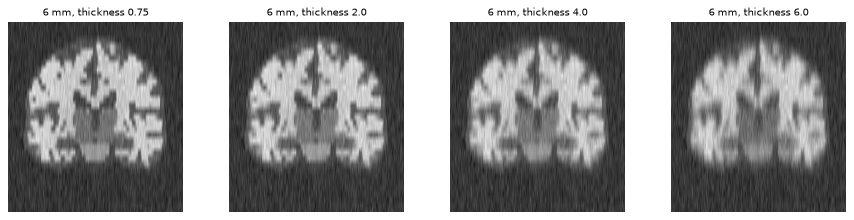

In [20]:
compare({f'6 mm, thickness {t}': (gen, dict(acquisition=aniso_acq(2, 6., t))) for t in [0.75, 2., 4., 6.]},
        seed=8, motion=False, views=('coronal',))

**Direction** of the slices: axis 0 (sagittal), 1 (coronal), 2 (axial). The axial slice shows the thick slices of axes 0 and 1. The coronal slice shows those of axes 0 and 2.

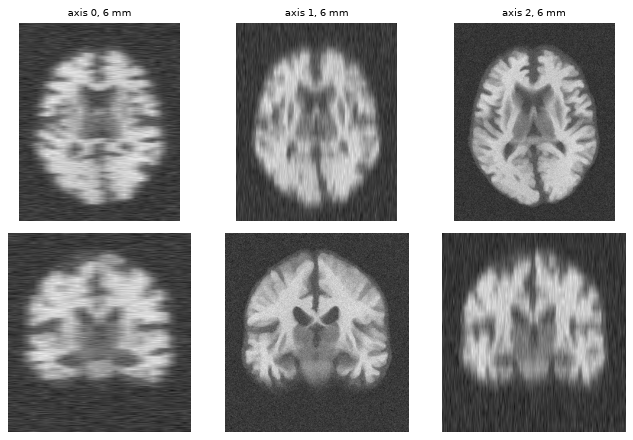

In [21]:
compare({f'axis {a}, 6 mm': (gen, dict(acquisition=aniso_acq(a, 6.))) for a in range(3)},
        seed=8, motion=False, views=('axial', 'coronal'))

Low-resolution **isotropic** acquisitions (`lowres_iso_prob`): all axes at once.

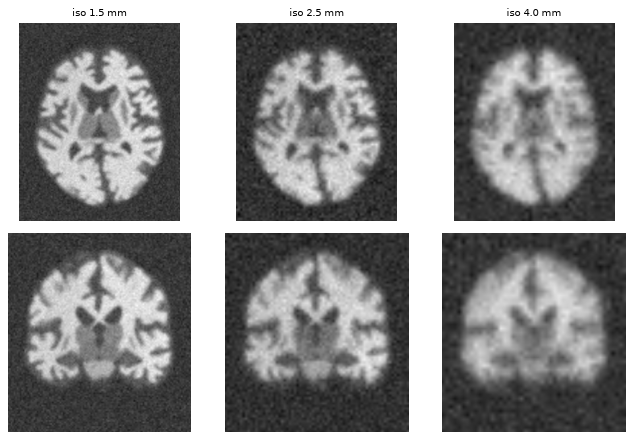

In [22]:
compare({f'iso {v} mm': (gen, dict(acquisition=iso_acq(v))) for v in [1.5, 2.5, 4.]},
        seed=8, motion=False)

### 9.5 Where the noise goes: `noise_space`

- `'lowres'` (default): noise is added **on the low-resolution grid**, before interpolating back. This is what happens in a real scanner: noise is independent across the *acquired* voxels. After interpolation it becomes **correlated** along the slice direction, with stripes in the coronal view.
- `'highres'`: noise is added at 0.75 mm **before** the resolution step (SynthSeg's order). The smoothing and downsampling then attenuate it strongly.

With the native acquisition there is no difference: the noise is added at 0.75 mm in both cases.

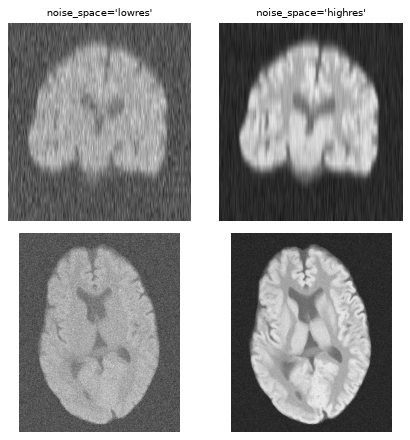

In [23]:
acq = aniso_acq(2, 5.0)
g_lo = gen.with_config(noise_sigma=(0.08, 0.08), noise_space='lowres')
g_hi = gen.with_config(noise_sigma=(0.08, 0.08), noise_space='highres')
compare({"noise_space='lowres'": g_lo, "noise_space='highres'": g_hi},
        seed=9, acquisition=acq, motion=False, views=('coronal', 'axial'))

### 9.6 Random samples with the defaults

Everything together, with drawn acquisitions (row 2: coronal):

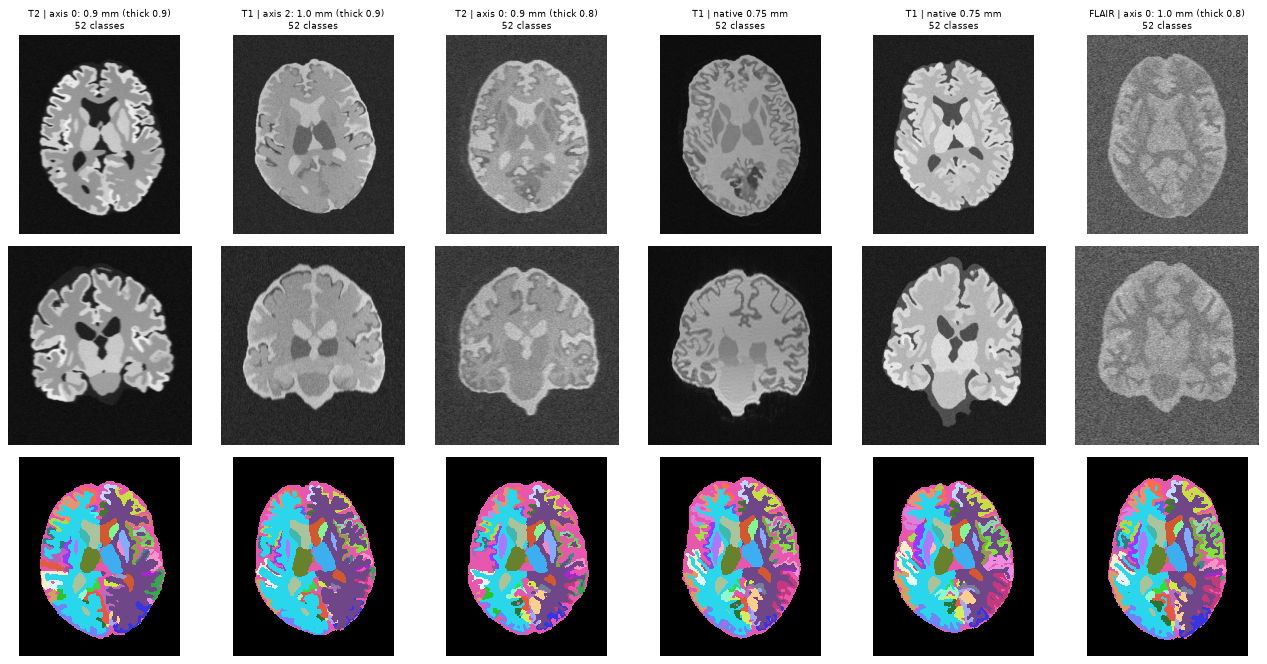

In [24]:
view(gen, n=6, seed=100);

## 10. Coupling tree ↔ resolution

With `tree_resolution='acquisition'`, the resolution that decides node visibility is the **coarsest spacing** of the acquisition. This is a conservative choice: in a 0.75×0.75×6 mm image a cortical parcel is clearly visible in-plane, but not along the 6 mm direction.

Consequences:

- The image never has intensity details that the resolution could not show. The intensity model and the image are consistent.
- `info['group_of']` / `info['class_names']` tell which labels are indistinguishable in *that* image, so they can be merged in the loss if desired.
- The proportion of "fine" images depends on the distribution of section 9.3.

Number of classes as a function of spacing (same contrast):

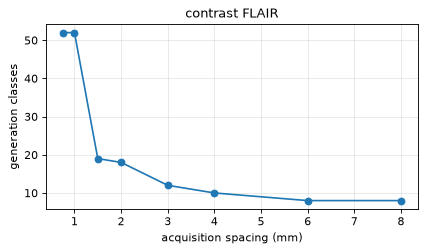

In [25]:
spacings = [0.75, 1., 1.5, 2., 3., 4., 6., 8.]
n_cls = []
for s in spacings:
    _, _, _, inf = draw(gen, 0, acquisition=aniso_acq(2, s) if s > .75 else NATIVE, motion=False)
    n_cls.append(len(inf['class_names']))
plt.figure(figsize=(6, 3)); plt.plot(spacings, n_cls, 'o-'); plt.grid(alpha=.3)
plt.xlabel('acquisition spacing (mm)'); plt.ylabel('generation classes')
plt.title(f"contrast {inf['contrast']}"); plt.show()

## 11. Playground: every parameter

✏️ Edit the `PARAMS` dictionary (it has **every** field, with the values from `freesurfer.json`) and run the cell. The samples are generated with `with_config`, so it is fast.

The fields `target_voxel`, `factor`, `background`, `output_labels` and `unassigned` change the label space or the grid. If you modify them, the cell builds a new generator (slower: it may super-resolve again if you change `target_voxel`/`factor`).

Call options:

- `ACQ = None` draws the acquisition. You can also use `NATIVE`, `aniso_acq(axis, spacing, thickness)` or `iso_acq(voxel)`.
- `MOTION = None` draws the motion; `True` or `False` force it.

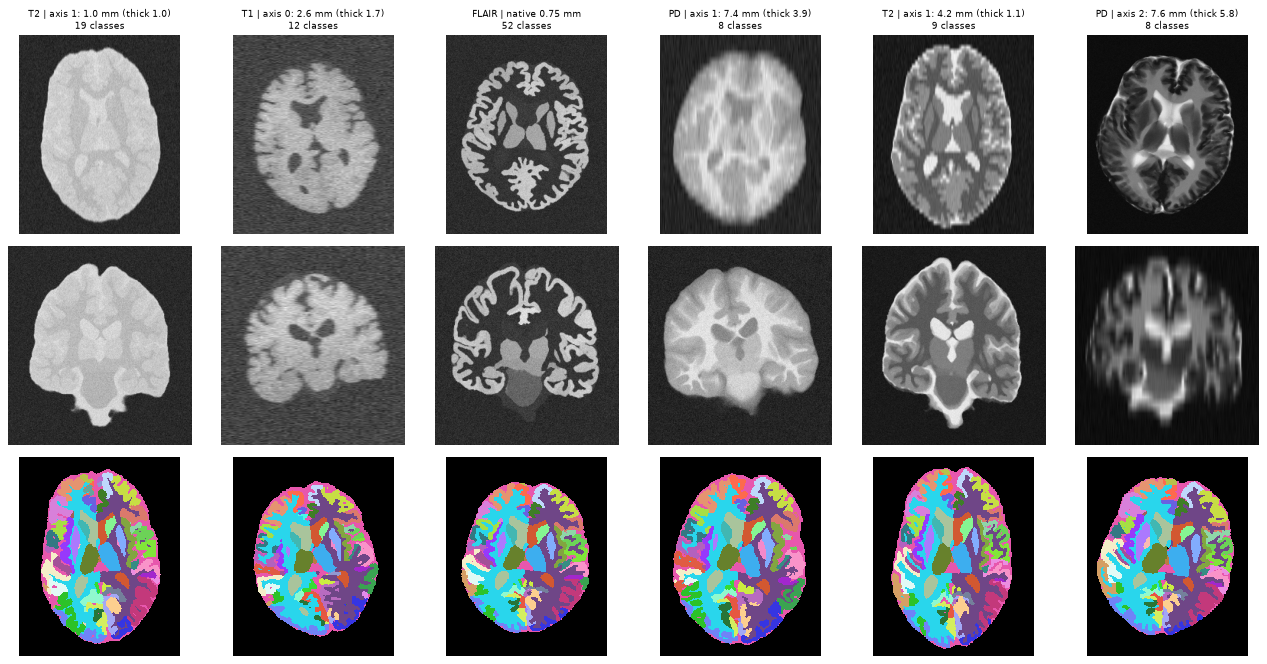

In [26]:
# ✏️ TRY IT: change whatever you like
PARAMS = dict(
    # grid and labels (changing them rebuilds the generator)
    target_voxel=0.75, factor=3, background=0, output_labels='templates', unassigned='background',
    # shape
    morpho_pairs=cfg.morpho_pairs, morpho_iter=(1, 4), morpho_prob=0.5,
    # deformation
    rotations=10., zooms=0.1, shears=0., translations_mm=0., elastic_dmax_mm=7.5, elastic_ctrl=7,
    # tree intensities
    colors_mu=(0., 255.), colors_sigma=(0.255, 2.55), min_sigma=0., intensity_scale=255.,
    tree_resolution='acquisition', resolution=None, contrasts=['T1', 'T2', 'FLAIR', 'PD'],
    # artefacts
    bias_prob=1.0, bias_vmax=0.5, bias_ctrl=5,
    motion_prob=0.3, motion_shots=3, motion_rotations=10., motion_translations_mm=10.,
    noise_sigma=(0.01, 0.1),
    # resolution
    lowres_prob=0.95, lowres_iso_prob=0.1, lowres_max_iso=4., lowres_max_aniso=8.,
    lowres_alpha=(1 / 1.03, 1.03), lowres_random_thickness=True, noise_space='lowres',
)
N, SEED = 6, 0
ACQ = None      # None | NATIVE | aniso_acq(2, 5.0) | iso_acq(3.0)
MOTION = None   # None | True | False

grid = {k: PARAMS[k] for k in tg.TreeGenerator._TEMPLATE_FIELDS}
if any(grid[k] != getattr(gen.cfg, k) for k in grid):
    print('the label space / grid changes -> new generator')
    cfg_play = tg.TreeGeneratorConfig.from_dict(PARAMS)
    gen_play = tg.TreeGenerator(tg.build_templates([SEG], TREE, cfg_play, CACHE, device=DEVICE),
                                TREE, cfg_play, device=DEVICE)
else:
    gen_play = gen.with_config(**{k: v for k, v in PARAMS.items() if k not in grid})
LCMAP = random_label_cmap(gen_play.nb_labels)
infos = view(gen_play, n=N, seed=SEED, acquisition=ACQ, motion=MOTION)

Everything that was drawn for each sample is in `info`:

In [27]:
for i, inf in enumerate(infos):
    a = inf['acquisition']
    print(f"sample {i}: contrast {inf['contrast']}, colors mu {np.round(inf['colors_mu'], 1)}, "
          f"{acq_title(a)}, tree @ {inf['resolution']:.2f} mm -> {len(inf['class_names'])} classes")

sample 0: contrast T2, colors mu [234.1 211.6 246.8], axis 1: 1.0 mm (thick 1.0), tree @ 1.04 mm -> 19 classes
sample 1: contrast T1, colors mu [166.2 201.1  23.9], axis 0: 2.6 mm (thick 1.7), tree @ 2.60 mm -> 12 classes
sample 2: contrast FLAIR, colors mu [241.7  14.4  21.6], native 0.75 mm, tree @ 0.75 mm -> 52 classes
sample 3: contrast PD, colors mu [154.4 231.7 119.7], axis 1: 7.4 mm (thick 3.9), tree @ 7.39 mm -> 8 classes
sample 4: contrast T2, colors mu [140.1  73.8 252.5], axis 1: 4.2 mm (thick 1.1), tree @ 4.22 mm -> 9 classes
sample 5: contrast PD, colors mu [  7.4 118.7 240.6], axis 2: 7.6 mm (thick 5.8), tree @ 7.58 mm -> 8 classes


## 12. Saving samples and generating datasets

`tg.save_sample` saves the image (float32) and the segmentation (**uint16**). With `labels=gen.labels` the raw values (2, 3, 1001, ...) are saved. Without that argument the indices `0..K-1` are saved, which is what nnU-Net needs.

In [28]:
os.makedirs('data/outputs/notebook', exist_ok=True)
tg.seed_everything(0)
img, seg, aff, info = gen_play()
tg.save_sample(img, seg, aff, 'data/outputs/notebook/example_img.nii.gz',
               'data/outputs/notebook/example_seg.nii.gz', labels=gen_play.labels)
s = nib.load('data/outputs/notebook/example_seg.nii.gz')
print('saved segmentation:', s.get_data_dtype(), s.shape, '| values:', np.unique(np.asarray(s.dataobj))[:8], '...')

# save the config used
with open('data/outputs/notebook/config.json', 'w') as f:
    json.dump(gen_play.cfg.to_dict(), f, indent=2)

saved segmentation: uint16 (240, 296, 260) | values: [ 0  2  4  5  7  8 10 11] ...


From the terminal:

```bash
conda activate nxb

# figures + samples; any parameter as an option (python run_example.py --help)
python run_example.py -n 8 --lowres-prob 1 --lowres-max-aniso 6 --noise-space highres

# nnU-Net dataset (imagesTr / labelsTr / dataset.json) from a JSON config
python tree_generator.py --seg seg1.nii.gz seg2.nii.gz --tree data/inputs/synthseg_ctx_tree.json \
    --config data/outputs/notebook/config.json --out /path/DatasetXXX -n 1000

# checks
python test_generator.py
```

## Summary

| I want... | parameter |
|---|---|
| more shape variety | `morpho_pairs`, `morpho_iter`, `elastic_dmax_mm`, `rotations`, `zooms` |
| more or less extreme contrasts | `colors_mu`, `colors_sigma` |
| more texture inside the tissues | `colors_sigma`, `min_sigma` |
| more/less inhomogeneity | `bias_vmax`, `bias_ctrl`, `bias_prob` |
| more/less motion | `motion_prob`, `motion_shots`, `motion_rotations`, `motion_translations_mm` |
| more/less noise | `noise_sigma`, `noise_space` |
| more low-resolution images | `lowres_prob` ↑, `lowres_max_aniso` ↑, `lowres_max_iso` ↑ |
| more fine images (small structures visible) | `lowres_prob` ↓, `lowres_max_aniso` ↓ |
| v0 behaviour (tree resolution independent of the acquisition) | `tree_resolution='config'`, `resolution=...`, `lowres_prob=0` |
| every tree label in the output | `output_labels='tree'` |